# Лекция 8. Ограничения-равенства: множители Лагранжа, LICQ и условия второго порядка

**Курс:** Вычислительная оптимизация · **Часть III. Ограничения-равенства** · Лекция 8 из 16 · 4 ноября 2026

**Материалы:** [конспект-ноутбук с кодом демонстраций](lecture08.ipynb) · [демо-ноутбук](demo08.ipynb) · [разбор упражнений](exercises08.ipynb)

В конспекте-ноутбуке три демо стоят после своих разделов: (a) — после §2, (b) — после §3, (c) — после §5.

---

> **Код в этом ноутбуке.** Три демо из [`demo08.ipynb`](demo08.ipynb) стоят после своих разделов. «Демо (a)» — условие первого порядка — после §2. «Демо (b)» — LICQ — после §3. «Демо (c)» — цепь на стержнях в IPOPT — после §5. Числа введения и подробности — только в `demo08.ipynb`. Вспомогательный код вынесен в [`l8helpers.py`](l8helpers.py), его подключает ячейка ниже. Нужен CasADi: `uv run --group casadi jupyter lab`, в Colab он ставится сам.

In [1]:
%matplotlib inline

from l8helpers import *  # палитра, окружность, сфера и плоскость, цепь на стержнях, портфель (см. файл рядом)

## Введение

### Задача 1. Ближайшая точка окружности

Найдём на единичной окружности точку, ближайшую к $a=(2,1)$:

$$
\min_{x\in\mathbb R^2}\ f(x)=\tfrac12\lVert x-a\rVert^2\qquad\text{при}\qquad g(x)=\tfrac12\big(x_1^2+x_2^2-1\big)=0 .
$$

Ответ виден глазами: это точка на луче к $a$, то есть $x^\ast=a/\lVert a\rVert=(0.894,\ 0.447)$.

Получим его условием касания из лекции 3. Почему градиенты должны быть параллельны:

- в минимуме сдвиг вдоль окружности не уменьшает $f$, поэтому линия уровня $f$ касается окружности;
- у касающихся кривых в точке касания общая нормаль;
- нормаль к линии уровня $f$ — это $\nabla f$, нормаль к окружности $g=0$ — это $\nabla g$.

Значит, $\nabla f=\lambda\nabla g$ для некоторого числа $\lambda$. Строгий вывод — в §2.

Здесь $\nabla f=x-a=(x_1-2,\ x_2-1)$ и $\nabla g=x=(x_1,\ x_2)$. Запишем равенство $\nabla f=\lambda\nabla g$ по компонентам и добавим само ограничение:

$$
x_1-2=\lambda x_1,\qquad x_2-1=\lambda x_2,\qquad x_1^2+x_2^2=1 .
$$

Первые два уравнения — две компоненты равенства градиентов, третье — ограничение. Три уравнения, три неизвестных: $x_1$, $x_2$, $\lambda$. У системы **два** решения:

| Точка $x$ | $\lambda$ | $f(x)$ |
|---|---|---|
| $(0.894,\ 0.447)$ | $-1.236$ | $0.764$ |
| $(-0.894,\ -0.447)$ | $3.236$ | $5.236$ |

<img src="img/00_circle_hook.png" width="750" alt="единичная окружность, точка a = (2, 1) и две точки на прямой через начало координат и a: ближайшая (0.894, 0.447) с λ = −1.236 и f = 0.764 и самая далёкая (−0.894, −0.447) с λ = 3.236 и f = 5.236; в обеих окружность уровня f вокруг a касается единичной окружности">

*Первое решение — ближайшая точка, второе — самая далёкая. Линия уровня $f$ касается окружности в обеих.*

**Условие касания находит кандидатов, но не говорит, где минимум.** Гессиан $\nabla^2f=I$ одинаков в обеих точках и тоже не помогает.

### Задача 2. Цепь на жёстких стержнях

Возьмём цепь из лекций 1 и 4–7, но короткую: три груза по 1 кг между опорами $(-2,1)$ и $(2,1)$. Пружины заменим жёсткими стержнями длины $\ell=1.25$ м. Цепь висит так, чтобы её потенциальная энергия была наименьшей:

$$
\min\ f=w\,(z_1+z_2+z_3)\qquad\text{при}\qquad g_j=(y_{j+1}-y_j)^2+(z_{j+1}-z_j)^2-\ell^2=0,\quad j=0,1,2,3 .
$$

Здесь $(y_i,z_i)$ — координаты груза $i$, а $w=9.81$ Н — его вес. Опоры — точки с номерами $0$ и $4$. Стержень $j$ соединяет точки $j$ и $j+1$. Равенство $g_j=0$ говорит: длина стержня $j$ равна $\ell$.

Ограничений четыре, и у каждого свой множитель. Условие касания для них выведем в §2:

$$
\nabla f=\lambda_0\nabla g_0+\lambda_1\nabla g_1+\lambda_2\nabla g_2+\lambda_3\nabla g_3 .
$$

Вместе с ограничениями получается система:

- $6$ уравнений условия касания — по два на груз, по $y_i$ и по $z_i$;
- $4$ уравнения $g_j=0$;
- $10$ неизвестных: $6$ координат и $4$ множителя.

IPOPT решает эту систему за 5 итераций. Цепь симметрична, поэтому разных множителей два:

| Стержни | $\lambda_j$ | $2\lvert\lambda_j\rvert\ell$ |
|---|---|---|
| $0$ и $3$, у опор | $-7.87$ | $19.7$ Н |
| $1$ и $2$, в середине | $-5.58$ | $14.0$ Н |

<img src="img/00_chain_hook.png" width="900" alt="цепь из трёх грузов на четырёх стержнях между опорами (−2, 1) и (2, 1), найденная IPOPT; у стержней подписаны натяжения: 19.7 Н у опор и 14.0 Н в середине">

*Числа $2\lvert\lambda_j\rvert\ell$ оказались натяжениями стержней в ньютонах. Никаких сил в задаче мы не задавали.*

**Почему множители — силы.** Разберём груз 1. Его координаты $y_1,z_1$ входят в $f$ и в два ограничения: $g_0$ (стержень к опоре) и $g_1$ (стержень к грузу 2). Выпишем компоненты условия касания по $y_1$ и по $z_1$:

$$
0=2\lambda_0\,(y_1-y_0)-2\lambda_1\,(y_2-y_1),
$$

$$
w=2\lambda_0\,(z_1-z_0)-2\lambda_1\,(z_2-z_1).
$$

Слева — производные $f$: по $y_1$ это ноль, по $z_1$ — вес $w$. Справа — производные $g_0$ и $g_1$, умноженные на множители. Остальные ограничения от груза 1 не зависят.

Обозначим точки $p_i=(y_i,z_i)$ и перенесём всё в одну сторону. Два уравнения станут одним векторным:

$$
\underbrace{(0,\ -w)}_{\text{вес}}+\underbrace{2\lambda_0\,(p_1-p_0)}_{\text{стержень 0}}+\underbrace{2\lambda_1\,(p_1-p_2)}_{\text{стержень 1}}=0 .
$$

Это **равновесие груза 1**: сумма трёх сил равна нулю.

- Вес $(0,-w)$ тянет груз вниз. Это $-\nabla f$ по координатам груза: сила равна минус градиенту энергии.
- Сила стержня 0 направлена вдоль него. Множитель $\lambda_0<0$, поэтому сила смотрит к опоре: стержень тянет груз. Её величина $2\lvert\lambda_0\rvert\ell=19.7$ Н.
- Сила стержня 1 направлена вдоль него, к грузу 2. Её величина $2\lvert\lambda_1\rvert\ell=14.0$ Н.

<img src="img/00_chain_forces.png" width="900" alt="слева: груз 1 и три стрелки — вес 9.8 Н вниз, сила стержня 0 19.7 Н к опоре, сила стержня 1 14.0 Н к грузу 2; справа: те же три стрелки, приложенные одна за другой, образуют замкнутый треугольник">

*Слева три силы на груз 1. Справа те же стрелки, приложенные одна за другой: треугольник замкнулся, сумма — ноль.*

Проверим по составляющим. Стержень 0 тянет влево с силой 13.1 Н, стержень 1 — вправо с той же силой. Вверх стержень 0 тянет с силой 14.7 Н. Вниз тянут вес 9.8 Н и стержень 1 с силой 4.9 Н.

У каждого груза те же два уравнения. **Условие касания — это равновесие сил, а множители Лагранжа — силы, с которыми ограничения держат решение.**

### Зачем это вам

Почти все задачи частей III и IV — с ограничениями. Метод Ньютона–Лагранжа (лекция 9) и солвер IPOPT решают одну и ту же систему уравнений. Сегодня мы её выведем и научимся проверять её решение.

**Главная тема лекции — касательное пространство.** Это направления, вдоль которых можно двигаться, не нарушая ограничений.

**Три вопроса лекции:**

1. Как записать условие минимума, если есть ограничения-равенства?
2. Когда это условие не работает?
3. Как отличить минимум от максимума?

**План:**

- §1 — что мы уже знаем;
- §2 — условие первого порядка и функция Лагранжа;
- §3 — условие LICQ;
- §4 — условие второго порядка;
- §5 — множители как силы и цены;
- §6 — что возвращают солверы.

## 1. Повторение: что знаем и чего нет

**Главная мысль.** Без ограничений в минимуме $\nabla f=0$. С ограничением $\nabla f\neq0$, но в лекции 3 он оказался перпендикулярен кривой.

Вспомним лекцию 3 (§6): прямоугольник наибольшей площади, вписанный в единичный круг. Пусть его вершины — $(\pm x_1,\ \pm x_2)$, где $x_1,x_2>0$. Тогда:

- вершины лежат на окружности: $x_1^2+x_2^2=1$;
- стороны равны $2x_1$ и $2x_2$, площадь — $4x_1x_2$;
- наибольшая площадь — то же, что наименьшее значение $-4x_1x_2$.

$$
\min\ f(x)=-4x_1x_2\qquad\text{при}\qquad g(x)=x_1^2+x_2^2-1=0 .
$$

Градиенты:

$$
\nabla f=(-4x_2,\ -4x_1),\qquad\nabla g=(2x_1,\ 2x_2) .
$$

В решении $x^\ast=(0.707,\ 0.707)$ они равны $\nabla f=(-2.83,\ -2.83)$ и $\nabla g=(1.41,\ 1.41)$. Значит, $\nabla f=-2\,\nabla g$, то есть $\lambda=-2$.

<img src="img/01_review.png" width="640" alt="задача лекции 3: единичная окружность, вписанный квадрат, линия уровня f = −2 (гипербола) касается окружности в x* = (0.707, 0.707); там ∇f и ∇g лежат на одной прямой, λ = −2">

*Вписан квадрат. Линия уровня $f$ касается окружности, и $\nabla f$ направлен против $\nabla g$.*

Это правило мы видели на картинке, без вывода и для одного ограничения. Сравним с тем, что знаем о задачах без ограничений из лекции 4:

| | Без ограничений (Л4) | С равенствами (Л3) |
|---|---|---|
| Первый порядок | $\nabla f=0$ | $\nabla f=\lambda\nabla g$ |
| Когда верно | всегда | ? |
| Второй порядок | $\nabla^2f\succ0$ | ? |

В правом столбце два вопроса, и ещё один скрыт в первой строке: что делать, если ограничений несколько. Это три вопроса лекции.

## 2. Условие первого порядка

**Главная мысль.** С ограничением двигаться можно только вдоль него. В минимуме производная $f$ вдоль такого движения равна нулю. Поэтому у $\nabla f$ нет касательной части.

### 2.1. Одно ограничение: окружность

Вернёмся к задаче 1:

$$
\min\ f(x)=\tfrac12\lVert x-a\rVert^2\qquad\text{при}\qquad g(x)=\tfrac12\big(x_1^2+x_2^2-1\big)=0,\qquad a=(2,1) .
$$

Точку окружности запишем через угол: $x(t)=(\cos t,\ \sin t)$. Скорость точки при движении по окружности:

$$
x'(t)=(-\sin t,\ \cos t)=(-x_2,\ x_1)=p .
$$

Вектор $p$ — **касательное направление**. Он перпендикулярен радиусу: $x^\top p=0$.

Как меняется $f$ при движении по окружности? По правилу дифференцирования сложной функции

$$
\frac{d}{dt}f\big(x(t)\big)=\nabla f(x)^\top p .
$$

Если это число не ноль, $f$ меняется при движении по окружности: в одну сторону растёт, в обратную уменьшается. Значит, точка не минимум.

<img src="img/02_circle_tangent.png" width="900" alt="слева: точка (0.5, 0.866) на окружности, ∇f и его касательная часть (оранжевая стрелка вдоль касательной); синяя дуга против касательной части подписана «движение сюда уменьшает f»; справа: точка (0.894, 0.447), ∇f и ∇g лежат на одной прямой, касательной части нет, λ = −1.236">

*Слева у $\nabla f$ есть касательная часть: двигаясь против неё по окружности, уменьшаем $f$. Справа касательной части нет — это минимум.*

В минимуме $\nabla f^\top p=0$. Значит, $\nabla f$ лежит на нормали к окружности, то есть параллелен $\nabla g=x$:

$$
\nabla f=\lambda\nabla g\quad\Longleftrightarrow\quad x-a=\lambda x .
$$

Это и есть система из введения.

### 2.2. Два ограничения: окружность в пространстве

Поднимем точку $a$ над плоскостью: $a=(2,1,1)$. Ищем ближайшую к ней точку той же окружности. В пространстве окружность задают **два** равенства:

$$
g_1(x)=\tfrac12\big(x_1^2+x_2^2+x_3^2-1\big)=0\ \ \text{(сфера)},\qquad g_2(x)=x_3=0\ \ \text{(плоскость)} .
$$

Сфера и плоскость пересекаются по окружности. Двигаться можно только вдоль неё. Такое направление $p\in\mathbb R^3$ перпендикулярно **обоим** градиентам:

$$
\nabla g_1^\top p=0,\qquad\nabla g_2^\top p=0 .
$$

Запишем оба условия одной матрицей. **Якобиан** ограничений $J$ — матрица, строки которой — градиенты ограничений:

$$
J=\begin{pmatrix}\nabla g_1^\top\\ \nabla g_2^\top\end{pmatrix}=\begin{pmatrix}x_1&x_2&x_3\\ 0&0&1\end{pmatrix},\qquad Jp=0 .
$$

Все $p$ с $Jp=0$ образуют **касательное пространство** $T$. Здесь это прямая, касательная к окружности.

В минимуме $\nabla f$ перпендикулярен $T$. Векторы, перпендикулярные $T$, — это комбинации строк $J$. Поэтому

$$
\nabla f=\lambda_1\nabla g_1+\lambda_2\nabla g_2=J^\top\lambda .
$$

Проверим числами. Ответ — та же точка $x^\ast=(0.894,\ 0.447,\ 0)$. В ней

$$
\nabla f=x^\ast-a=(-1.106,\ -0.553,\ -1),\qquad\lambda_1=-1.236,\qquad\lambda_2=-1 .
$$

<img src="img/03_sphere_plane.png" width="610" alt="трёхмерная картинка: плоскость x₃ = 0, единичная окружность в ней, точка a = (2, 1, 1) над плоскостью; в точке x* три стрелки: λ₁∇g₁ в плоскости к центру окружности, λ₂∇g₂ вертикально вниз и их сумма ∇f; пунктир — касательная прямая T">

*Красный $\nabla f$ — сумма двух нормалей: зелёная $\lambda_1\nabla g_1$ лежит в плоскости, фиолетовая $\lambda_2\nabla g_2$ смотрит вниз.*

Множитель $\lambda_1$ тот же, что на плоскости. Новый множитель $\lambda_2=-1$ — вклад плоскости: третья компонента $\nabla f$ равна $-1$.

### 2.3. Общий случай: функция Лагранжа

Пусть переменных $n$, а ограничений $m$. Задача:

$$
\min_x\ f(x)\qquad\text{при}\qquad g(x)=0 .
$$

*Размеры:* $x\in\mathbb R^n$, $f(x)$ — число, $g(x)\in\mathbb R^m$.

Как в §2.2, в минимуме $\nabla f$ — комбинация градиентов ограничений:

$$
\nabla f(x)=J(x)^\top\lambda .
$$

*Размеры:* $\nabla f\in\mathbb R^n$; якобиан $J$ — матрица $m\times n$, её строка $j$ — это $\nabla g_j^\top$; $\lambda\in\mathbb R^m$ — **множители Лагранжа** (*Lagrange multipliers*), по одному на ограничение.

Условие удобно записать через **функцию Лагранжа**:

$$
L(x,\lambda)=f(x)-\lambda^\top g(x),\qquad\nabla_xL=\nabla f-J^\top\lambda .
$$

*Размеры:* $L$ — число, $\nabla_xL\in\mathbb R^n$. Знак минус — как в лекции 3.

Условие первого порядка вместе с самими ограничениями:

$$
\boxed{\ \nabla_xL(x,\lambda)=0,\qquad g(x)=0\ }
$$

*Размеры:* $n$ уравнений и ещё $m$ уравнений. Неизвестных столько же: $n$ координат $x$ и $m$ множителей $\lambda$.

| Задача | $n$ | $m$ | Уравнений $n+m$ |
|---|---|---|---|
| задача 1: окружность | $2$ | $1$ | $3$ |
| §2.2: окружность в пространстве | $3$ | $2$ | $5$ |
| задача 2: цепь | $6$ | $4$ | $10$ |

В лекции 9 мы будем решать эту систему методом Ньютона.

### Демо (a). Условие первого порядка (раздел 2)

**Что проверяем.** Система задачи 1 находит обе точки касания. В них у $\nabla f$ нет касательной части, а в других точках окружности — есть. С двумя ограничениями множителей два.

**Шаг 1. Что делает ячейка.** Функция `circle_system` получает вектор неизвестных $z=(x_1,x_2,\lambda)$. Она возвращает левые части трёх уравнений задачи 1, перенесённые в одну сторону:

$$
x_1-2-\lambda x_1,\qquad x_2-1-\lambda x_2,\qquad x_1^2+x_2^2-1 .
$$

Решение системы — такое $z$, где все три числа равны нулю. Его ищет `fsolve` из SciPy: итерации типа метода Ньютона от стартовой точки. Из старта справа он находит ближнюю точку, из старта слева — дальнюю.

In [2]:
from scipy.optimize import fsolve

a = A_CIRCLE                                           # a = (2, 1) — точка, к которой ищем ближайшую

def circle_system(z):
    """Левые части трёх уравнений задачи 1 при a = (2, 1). Решение системы — z, где все три равны нулю."""
    x1, x2, lam = z                                    # неизвестные: координаты точки и множитель
    return [x1 - 2 - lam * x1,                         # первая компонента grad f = lambda grad g
            x2 - 1 - lam * x2,                         # вторая компонента
            x1**2 + x2**2 - 1]                         # точка лежит на окружности

sols = []
for start in ([1.0, 0.5, 0.0], [-1.0, -0.5, 0.0]):    # стартовые (x1, x2, lambda): справа и слева
    z = fsolve(circle_system, start, xtol=1e-14)       # решение системы из этого старта
    sols.append(z)
    print(f"старт {start}: x = ({z[0]:+.4f}, {z[1]:+.4f}), lambda = {z[2]:+.4f}, невязки = {np.abs(circle_system(z)).max():.0e}")

старт [1.0, 0.5, 0.0]: x = (+0.8944, +0.4472), lambda = -1.2361, невязки = 1e-16
старт [-1.0, -0.5, 0.0]: x = (-0.8944, -0.4472), lambda = +3.2361, невязки = 1e-16


**Что видим.** Два старта — два решения, те же, что в части (0): $\lambda=-1.236$ и $\lambda=3.236$. Невязки — машинный ноль.

**Шаг 2. Что делает ячейка.** Касательная часть $\nabla f$ — это проекция $\nabla f$ на касательную к окружности. Ограничение одно, поэтому якобиан — одна строка $J=\nabla g^\top=x^\top$. Функция `null_space(J)` возвращает единичный вектор $Z$ с $JZ=0$, то есть направление касательной. Касательная часть — число $Z^\top\nabla f$. Считаем его в двух решениях и в точке $(0.5,\ 0.866)$.

In [3]:
grad_f = lambda x: x - a                               # grad f для f = 1/2 |x - a|^2
grad_g = lambda x: x                                   # grad g для g = 1/2 (|x|^2 - 1)

def tangent_part(x):
    """Касательная часть grad f в точке x окружности: Z^T grad f, где Z — единичная касательная."""
    J = grad_g(x).reshape(1, -1)                       # якобиан: одна строка grad g^T
    Z = null_space(J)                                  # 2 x 1 — касательное направление, J Z = 0
    return (Z.T @ grad_f(x)).item()                    # проекция grad f на касательную

for name, x in (("ближняя точка", sols[0][:2]), ("дальняя точка", sols[1][:2]), ("точка (0.5, 0.866)", np.array([0.5, np.sqrt(3) / 2]))):
    print(f"{name:18s}: касательная часть grad f = {tangent_part(x):+.4f}")

ближняя точка     : касательная часть grad f = +0.0000
дальняя точка     : касательная часть grad f = -0.0000
точка (0.5, 0.866): касательная часть grad f = +1.2321


**Что видим.** В обоих решениях касательная часть — ноль: условие первого порядка выполнено. В точке $(0.5,\ 0.866)$ она равна $1.232$ по модулю. Значит, там $f$ меняется при движении по окружности: сдвиг против касательной части уменьшает $f$. Это картинка 02 конспекта.

**Шаг 3. Что делает ячейка.** Два ограничения: окружность в пространстве как пересечение сферы $\tfrac12(\lVert x\rVert^2-1)=0$ и плоскости $x_3=0$, точка $a=(2,1,1)$. Функция `sphere_plane()` находит ближайшую точку и строит якобиан $J$ — матрицу $2\times3$, по строке на ограничение. Множители она находит из $\nabla f=J^\top\lambda$ методом наименьших квадратов: три уравнения на два неизвестных. Если невязка — ноль, разложение $\nabla f$ по двум нормалям точное.

In [4]:
xs, gf, J, lam, T = sphere_plane()                                   # окружность = сфера ∩ плоскость, a = (2, 1, 1)
print(f"x* = {xs.round(3)},  grad f = {gf.round(3)}")
print(f"J =\n{J.round(3)}\nrank J = {np.linalg.matrix_rank(J)}")
print(f"lambda = {lam.round(3)}   (в конспекте -1.236 и -1);  |grad f - J^T lambda| = {np.linalg.norm(gf - J.T @ lam):.1e}")
print(f"базис T = {T.ravel().round(3)},  |J T| = {np.abs(J @ T).max():.1e}")

x* = [0.894 0.447 0.   ],  grad f = [-1.106 -0.553 -1.   ]
J =
[[0.894 0.447 0.   ]
 [0.    0.    1.   ]]
rank J = 2
lambda = [-1.236 -1.   ]   (в конспекте -1.236 и -1);  |grad f - J^T lambda| = 2.5e-16
базис T = [ 0.447 -0.894  0.   ],  |J T| = 1.3e-17


**Что видим.** $\lambda=(-1.236,\ -1)$, невязка — машинный ноль: $\nabla f$ точно раскладывается по двум нормалям. Ранг $J$ равен 2, ограничения независимы. Касательное пространство — один вектор, касательная к окружности в плоскости $x_3=0$.

**Шаг 4. Что делает ячейка.** Рисует обе точки. Линии уровня $f$ — окружности вокруг $a$. Две из них касаются единичной окружности в найденных точках. Красная стрелка — $\nabla f$, зелёная — $\nabla g$.

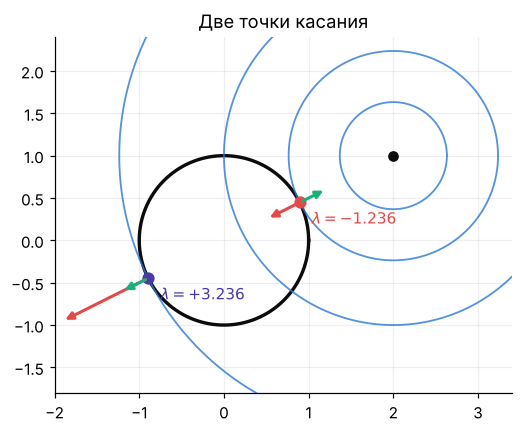

In [5]:
fig, ax = plt.subplots(figsize=(6, 4.2))
unit_circle(ax)                                                         # ограничение g = 0
level_circles(ax, a, [0.5 * np.sum((z[:2] - a) ** 2) for z in sols] + [0.2, 2.0], color=BLUE)   # линии уровня f, две — касаются
for z, col in zip(sols, (RED, VIOLET)):
    x = z[:2]
    ax.annotate("", x + 0.35 * grad_f(x), x, arrowprops=dict(arrowstyle="-|>", color=RED, lw=2))       # grad f
    ax.annotate("", x + 0.35 * grad_g(x), x, arrowprops=dict(arrowstyle="-|>", color=AQUA, lw=2))      # grad g
    ax.plot(*x, "o", color=col, ms=7); ax.annotate(f"$\\lambda={z[2]:+.3f}$", x, (8, -14), textcoords="offset points", color=col)
ax.plot(*a, "o", color=INK); ax.set_aspect("equal"); ax.set_xlim(-2, 3.4); ax.set_ylim(-1.8, 2.4)
ax.set_title("Две точки касания"); plt.show()

**Что видим.** В обеих точках стрелки лежат на одной прямой — на нормали к окружности. В ближней точке они направлены в разные стороны ($\lambda<0$), в дальней — в одну ($\lambda>0$).

## 3. LICQ

**Главная мысль.** Формула $T=\{p:\ Jp=0\}$ верно описывает направления движения, только если градиенты ограничений линейно независимы. Иначе она даёт направления, по которым двигаться нельзя, и условие касания в минимуме может не выполняться. Независимость градиентов называется LICQ.

### 3.1. Пример: плоскость касается сферы

Вернёмся к окружности из §2.2 и поднимем плоскость на высоту $c$:

$$
\min\ \tfrac12\lVert x-a\rVert^2\qquad\text{при}\qquad g_1(x)=\tfrac12\big(\lVert x\rVert^2-1\big)=0,\quad g_2(x)=x_3-c=0,\qquad a=(2,1,1) .
$$

При $c<1$ плоскость режет сферу по окружности. Нормали $\nabla g_1$ и $\nabla g_2$ не параллельны, и всё как в §2.2.

При $c=1$ плоскость касается сферы в точке $(0,0,1)$. Других допустимых точек нет, поэтому минимум — она. Нормали в ней параллельны:

$$
\nabla g_1=(0,\ 0,\ 1),\qquad\nabla g_2=(0,\ 0,\ 1) .
$$

- Система $Jp=0$ сводится к одному уравнению $p_3=0$. Формула объявляет касательным пространством всю горизонтальную плоскость. Но двигаться из точки некуда: **касательного пространства у множества нет.**
- Градиент $\nabla f=(-2,\ -1,\ 0)$ горизонтален, а $J^\top\lambda=(0,\ 0,\ \lambda_1+\lambda_2)$ вертикален. **Равенство $\nabla f=J^\top\lambda$ не выполняется ни при каких $\lambda$.**

<img src="img/04_sphere_touch.png" width="900" alt="вид сбоку: сфера — единичная окружность, плоскость x₃ = c — горизонтальная прямая; слева c = 0.6: прямая режет окружность, в точке x* нормали ∇g₁ и ∇g₂ не параллельны; справа c = 1: прямая касается окружности сверху, обе нормали смотрят вверх, ∇f горизонтален">

*Вид сбоку: сфера — окружность, плоскость — прямая. Слева $c=0.6$, нормали не параллельны. Справа $c=1$: нормали совпали, а $\nabla f$ горизонтален.*

Множители чувствуют касание заранее: при $c=0.9,\ 0.99,\ 0.999$ первый множитель равен $-4.1,\ -14.9,\ -49$.

<img src="img/10_plane_touch.gif" width="680" alt="анимация: плоскость поднимается к верху сферы, окружность пересечения сжимается в точку, нормали поворачиваются к одному направлению, в заголовке растёт по модулю λ₁">

*Плоскость поднимается. Окружность сжимается в точку, угол между нормалями уходит в ноль, а $\lambda_1$ — в минус бесконечность.*

### 3.2. Условие LICQ и теорема

**Определение.** В точке $x$ выполнено **LICQ** (*linear independence constraint qualification*, условие линейной независимости), если градиенты ограничений линейно независимы: $\operatorname{rank}J(x)=m$. Для одного ограничения это $\nabla g(x)\neq0$.

**Теорема (необходимое условие первого порядка).** Пусть $f$ и $g$ непрерывно дифференцируемы, $x^\ast$ — локальный минимум $f$ при $g(x)=0$, и в $x^\ast$ выполнено LICQ. Тогда существует единственный $\lambda^\ast\in\mathbb R^m$, при котором $\nabla_xL(x^\ast,\lambda^\ast)=0$.

- *Почему:* при LICQ решения $Jp=0$ — ровно направления движения по поверхности, как в §2.2. Поэтому $\nabla f$ перпендикулярен им всем и равен $J^\top\lambda$.
- *Чего не обещает:* что решение системы — минимум. У окружности два решения, и одно из них — максимум.
- *Идея доказательства:* при LICQ теорема о неявной функции записывает поверхность как $x=\psi(u)$, $u\in\mathbb R^{n-m}$. Задача $\min\tilde f(u)$, $\tilde f(u)=f(\psi(u))$, — уже без ограничений. Полное доказательство — в разборе упражнения 8.6.

### 3.3. Ограничение, записанное дважды

На практике LICQ чаще ломается проще: одно ограничение записали дважды. Пример — ближайшая к $a=(2,1)$ точка прямой $x_1+x_2=1$:

| Запись ограничения | $\operatorname{rank}J$ | Множители от IPOPT |
|---|---|---|
| $x_1+x_2=1$ | $1$ | $-1$ |
| то же дважды | $1$ | $-0.5$ и $-0.5$ |

Ответ один и тот же: $x^\ast=(1,0)$. Но во втором случае подходит любая пара с $\lambda_1+\lambda_2=-1$, и IPOPT выбрал одну из них. В лекции 9 повторённое ограничение даст вырожденную матрицу системы.

**Правило: ограничения не повторяют и не выводят одно из другого.**

### Демо (b). LICQ (раздел 3)

**Что проверяем.** Плоскость $x_3=c$ поднимается к верху сферы. При $c<1$ IPOPT находит точку и множители, и $\lambda_1=1-\sqrt5/\sqrt{1-c^2}$. При $c=1$ нормали параллельны: формула $Jp=0$ даёт целую плоскость, точных $\lambda$ нет, а множители IPOPT огромны.

**Шаг 1. Что делает ячейка.** Решает задачу §3.1 в CasADi при $c=0,\ 0.9,\ 0.99,\ 0.999,\ 1$. Функция `solve_eq` вызывает IPOPT. Она возвращает точку, множители в нашем знаке, число итераций и ранг $J$ в ответе.

- `ca.SX.sym("x", 3)` — символьный вектор $x=(x_1,x_2,x_3)$.
- `ca.vertcat(g1, g2)` — два ограничения одним вектором.
- Внутри `solve_eq`: `ca.nlpsol(..., "ipopt", ...)` строит солвер, `lbg=0, ubg=0` делает ограничения равенствами, а $-$`lam_g` — наши множители (§6).

Рядом печатается точное $\lambda_1=1-\sqrt5/\sqrt{1-c^2}$ (упражнение 8.2).

In [6]:
x = ca.SX.sym("x", 3)                                                  # символьный вектор x = (x1, x2, x3)
f = 0.5 * ca.sumsqr(x - ca.DM(A_SPACE))                                # f = 1/2 |x - a|^2, a = (2, 1, 1)
print(f"{'c':>6s} {'lambda1 IPOPT':>14s} {'точно':>8s} {'итераций':>9s} {'rank J':>7s}")
for c in (0.0, 0.9, 0.99, 0.999, 1.0):
    g = ca.vertcat(0.5 * (ca.sumsqr(x) - 1), x[2] - c)                 # сфера и плоскость x3 = c
    xs, lam, it, rk = solve_eq(x, f, g, [0.5, 0.5, c])                 # IPOPT из точки (0.5, 0.5, c)
    exact = f"{1 - np.sqrt(5) / np.sqrt(1 - c**2):8.3f}" if c < 1 else "     нет"
    print(f"{c:6.3f} {lam[0]:14.4g} {exact} {it:9d} {rk:7d}")
print("в конспекте: -4.1, -14.9, -49 при c = 0.9, 0.99, 0.999")

     c  lambda1 IPOPT    точно  итераций  rank J


 0.000         -1.236   -1.236         5       2
 0.900          -4.13   -4.130         5       2
 0.990         -14.85  -14.851         8       2
 0.999         -49.01  -49.013        10       2
 1.000     -2.122e+08      нет        47       1
в конспекте: -4.1, -14.9, -49 при c = 0.9, 0.99, 0.999


**Что видим.** При $c<1$ множитель IPOPT совпадает с формулой и растёт по модулю: $-4.13$, $-14.85$, $-49.0$. Итераций всё больше: 5, 8, 10. При $c=1$ ранг $J$ падает до 1. IPOPT всё равно находит точку $(0,0,1)$, но за 47 итераций, а множитель $-2\cdot10^8$ ничего не значит.

**Шаг 2. Что делает ячейка.** Сравнивает касательное пространство по формуле при $c=0$ и $c=1$. Функция `sphere_plane(c=c)` строит якобиан $J$ в ближайшей точке и базис $T$ — `null_space(J)`. Невязка $\min_\lambda\lVert\nabla f-J^\top\lambda\rVert$ показывает, есть ли подходящие $\lambda$. Картинка — вид сбоку при $c=1$.

c = 0.0: x* = [0.894 0.447 0.   ], rank J = 2, T по формуле — размерность 1, невязка 0.000
c = 1.0: x* = [0. 0. 1.], rank J = 1, T по формуле — размерность 2, невязка 2.236


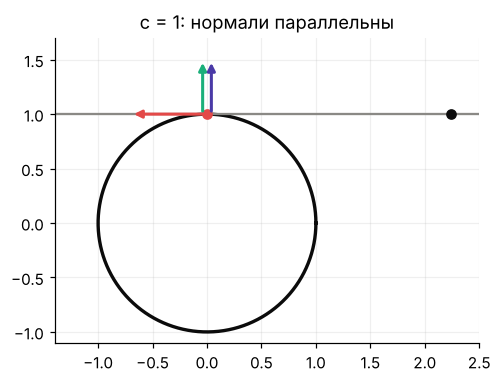

In [7]:
for c in (0.0, 1.0):
    xs, gf, J, lam, T = sphere_plane(c=c)                              # точка, grad f, якобиан, лучшие lambda, базис T
    res = np.linalg.norm(gf - J.T @ lam)                               # 0, если grad f = J^T lambda точно
    print(f"c = {c}: x* = {xs.round(3)}, rank J = {np.linalg.matrix_rank(J)}, "
          f"T по формуле — размерность {T.shape[1]}, невязка {res:.3f}")
fig, ax = plt.subplots(figsize=(5.6, 3.6))
unit_circle(ax)                                                        # сфера сбоку
ax.plot([-1.4, 2.5], [1, 1], color=GRAY)                               # плоскость x3 = 1 касается сферы
for dx, col in ((-0.04, AQUA), (0.04, VIOLET)):                        # grad g1 и grad g2: обе нормали вверх
    ax.annotate("", (dx, 1.5), (dx, 1.0), arrowprops=dict(arrowstyle="-|>", color=col, lw=2))
ax.annotate("", (-0.7, 1.0), (0, 1.0), arrowprops=dict(arrowstyle="-|>", color=RED, lw=2))   # grad f горизонтален
ax.plot(0, 1, "o", color=RED); ax.plot(np.sqrt(5), 1, "o", color=INK)  # x* = (0, 0, 1) и a — сбоку
ax.set_aspect("equal"); ax.set_xlim(-1.4, 2.5); ax.set_ylim(-1.1, 1.7); ax.set_title("c = 1: нормали параллельны"); plt.show()

**Что видим.** При $c=0$ ранг 2, $T$ — прямая, невязка 0: $\nabla f$ точно раскладывается по нормалям. При $c=1$ ранг 1 и формула даёт плоскость, а невязка $2.236=\sqrt5$: горизонтальный $\nabla f$ не собрать из вертикальных нормалей.

**Шаг 3. Что делает ячейка.** Задача — ближайшая к $a=(2,1)$ точка прямой $x_1+x_2=1$. Ответ $x^\ast=(1,0)$, множитель $\lambda=-1$. Задаём задачу в CasADi трижды: с одним ограничением, с тем же ограничением дважды и с парой $g$ и $2g$.

- `ca.SX.sym("x", 2)` создаёт символьный вектор $x$ из двух компонент.
- `ca.nlpsol(..., "ipopt", {"x": x, "f": f, "g": g})` строит солвер IPOPT для задачи $\min f$ при ограничениях $g$.
- `lbg=0, ubg=0` — нижняя и верхняя границы для $g$, то есть $0\le g\le0$: это равенство.
- `lam_g` — множители, которые вернул солвер. Знак у них противоположный нашему (§6), поэтому печатаем $-$`lam_g`.

In [8]:
x = ca.SX.sym("x", 2)                                                  # символьный вектор x = (x1, x2)
f = 0.5 * ca.sumsqr(x - ca.DM([2, 1]))                                 # f = 1/2 |x - a|^2
g1 = x[0] + x[1] - 1                                                   # ограничение x1 + x2 - 1 = 0
for name, g in (("одно ограничение", g1), ("то же дважды", ca.vertcat(g1, g1)), ("g и 2g", ca.vertcat(g1, 2 * g1))):
    s = ca.nlpsol("s", "ipopt", {"x": x, "f": f, "g": g}, {"ipopt.print_level": 0, "print_time": 0, "ipopt.sb": "yes"})
    sol = s(x0=[0, 0], lbg=0, ubg=0)                                   # lbg = ubg = 0: ограничения — равенства
    J = ca.Function("J", [x], [ca.jacobian(g, x)])(sol["x"]).full()    # якобиан ограничений в решении
    print(f"{name:18s}: x* = {np.array(sol['x']).ravel().round(6)}, rank J = {np.linalg.matrix_rank(J)}, "
          f"lambda (наш знак) = {(-np.array(sol['lam_g']).ravel()).round(4)}")

одно ограничение  : x* = [1. 0.], rank J = 1, lambda (наш знак) = [-1.]
то же дважды      : x* = [1. 0.], rank J = 1, lambda (наш знак) = [-0.5 -0.5]
g и 2g            : x* = [1. 0.], rank J = 1, lambda (наш знак) = [-0.2 -0.4]


**Что видим.** Ответ везде $x^\ast=(1,0)$, но ранг $J$ равен 1 при двух ограничениях: LICQ нарушено. Множители не единственны. Для повторённого ограничения подходит любая пара с $\lambda_1+\lambda_2=-1$, и IPOPT делит пополам. Для пары $g$ и $2g$ подходит любая пара с $\lambda_1+2\lambda_2=-1$, и IPOPT выбрал $-0.2$ и $-0.4$.

## 4. Условие второго порядка

**Главная мысль.** Минимум от максимума отличает кривизна $f$ вдоль ограничения. Её даёт функция Лагранжа: к кривизне $f$ добавляется кривизна ограничений.

### 4.1. Пример: две параболы

Задача:

$$
\min\ f(x)=x_2\qquad\text{при}\qquad g(x)=x_2-c\,x_1^2=0 .
$$

Функция $f$ линейна, $\nabla^2f=0$. Градиенты в нуле:

$$
\nabla f=(0,\ 1),\qquad\nabla g=(-2cx_1,\ 1)=(0,\ 1) .
$$

Значит, $\lambda=1$ при любом $c$. Условие первого порядка выполнено и при $c=1$, и при $c=-1$.

**Вопрос залу.** При $c=1$ ноль — минимум: парабола смотрит вверх. А что в нуле при $c=-1$?

<img src="img/05_parabola_curvature.png" width="900" alt="две панели: f = x₂ на параболе x₂ = x₁² (минимум в нуле) и на параболе x₂ = −x₁² (максимум в нуле); линии уровня f горизонтальны; в нуле на обеих панелях ∇f = ∇g = (0, 1), λ = 1">

*При $c=-1$ парабола смотрит вниз, и ноль — максимум $x_2$ на ней. Первый порядок одинаков, а ответ разный.*

Посчитаем $f$ вдоль параболы. Точку параболы запишем как $x(t)=(t,\ ct^2)$. Тогда

$$
f\big(x(t)\big)=ct^2,\qquad\frac{d^2}{dt^2}f\big(x(t)\big)=2c .
$$

Знак $c$ и решает. Ту же величину даёт функция Лагранжа:

$$
\nabla^2_{xx}L=\nabla^2f-\lambda\nabla^2g=0-1\cdot\begin{pmatrix}-2c&0\\0&0\end{pmatrix}=\begin{pmatrix}2c&0\\0&0\end{pmatrix} .
$$

Вдоль касательного направления $p=(1,0)$:

$$
p^\top\nabla^2_{xx}L\,p=2c .
$$

**Вся кривизна пришла от ограничения** — через слагаемое $-\lambda\nabla^2g$.

### 4.2. Редуцированный гессиан и теорема

В общем случае считаем вторую производную $f$ вдоль кривой на поверхности. Пусть $x(0)=x^\ast$ и $x'(0)=p\in T$. Ответ тот же, что у параболы:

$$
\frac{d^2}{dt^2}f\big(x(t)\big)\Big|_{t=0}=p^\top\nabla^2_{xx}L(x^\ast,\lambda^\ast)\,p .
$$

Слагаемое с ускорением $x''(0)$ сокращается благодаря $\nabla f=J^\top\lambda$ (упражнение 8.6).

Пусть $Z$ — матрица, столбцы которой — базис $T$. При LICQ в $T$ ровно $n-m$ независимых направлений, поэтому размер $Z$ — $n\times(n-m)$. В SciPy её даёт `scipy.linalg.null_space(J)`. Любое $p\in T$ записывается как $p=Zw$, и все кривизны вдоль $T$ собирает матрица

$$
Z^\top\nabla^2_{xx}L\,Z\qquad\text{размера }(n-m)\times(n-m) .
$$

Это **редуцированный гессиан** (*reduced Hessian*).

**Что обещает теорема.** Если редуцированный гессиан положительно определён (все собственные числа больше нуля), точка — строгий минимум.

**Почему.** Вдоль каждой допустимой кривой $f$ растёт, как парабола с положительной кривизной.

**Чего не обещает.** Ничего о направлениях вне $T$: там $\nabla^2_{xx}L$ может быть любым (упражнение 8.3).

**Теорема (условия второго порядка).** Пусть $f$ и $g$ дважды непрерывно дифференцируемы, в $x^\ast$ выполнено LICQ, $\nabla_xL(x^\ast,\lambda^\ast)=0$ и $g(x^\ast)=0$.

- *Необходимо:* если $x^\ast$ — локальный минимум, то $Z^\top\nabla^2_{xx}L\,Z\succeq0$.
- *Достаточно:* если $Z^\top\nabla^2_{xx}L\,Z\succ0$, то $x^\ast$ — строгий локальный минимум.

**Идея доказательства.** В параметризации $x=\psi(u)$ из §3.2

$$
\nabla^2\tilde f(u^\ast)=Z^\top\nabla^2_{xx}L\,Z,\qquad Z=\psi'(u^\ast) .
$$

У функции $\tilde f$ ограничений нет. Поэтому работают условия лекции 4: $\nabla^2\tilde f\succeq0$ необходимо, $\nabla^2\tilde f\succ0$ достаточно.

### 4.3. Ответ для окружности

Вернёмся к задаче 1:

$$
\min\ f(x)=\tfrac12\lVert x-a\rVert^2\qquad\text{при}\qquad g(x)=\tfrac12\big(x_1^2+x_2^2-1\big)=0,\qquad a=(2,1) .
$$

Здесь $\nabla^2f=I$ и $\nabla^2g=I$, поэтому

$$
\nabla^2_{xx}L=(1-\lambda)\,I .
$$

Касательное пространство — прямая с базисом $Z=(-x_2,\ x_1)^\top$. Редуцированный гессиан — число $1-\lambda$:

| Точка | $\lambda$ | $Z^\top\nabla^2_{xx}L\,Z$ | Вывод |
|---|---|---|---|
| $(0.894,\ 0.447)$ | $-1.236$ | $+2.236$ | минимум |
| $(-0.894,\ -0.447)$ | $3.236$ | $-2.236$ | максимум |

<img src="img/06_circle_cut.png" width="800" alt="f в точке окружности как функция угла θ: минимум 0.764 в ближней точке с кривизной +2.236 и максимум 5.236 в дальней с кривизной −2.236; пунктиром — параболы с этими кривизнами">

*$f$ вдоль окружности как функция угла. Вторая производная в ближней точке равна $+2.236$, в дальней $-2.236$. Это и есть редуцированный гессиан.*

Таблица из §1 заполнена:

| | Без ограничений (Л4) | С равенствами |
|---|---|---|
| Первый порядок | $\nabla f=0$ | $\nabla f=J^\top\lambda$ |
| Когда верно | всегда | при LICQ |
| Второй порядок | $\nabla^2f\succ0$ | $Z^\top\nabla^2_{xx}L\,Z\succ0$ |

## 5. Множители: силы и цены

**Главная мысль.** Множитель — сила, с которой ограничение держит решение. Он же — цена ограничения: насколько изменится оптимум, если ограничение сдвинуть.

### 5.1. Цепь на стержнях: множитель — натяжение

Вернёмся к задаче 2:

$$
\min\ f=w\,(z_1+z_2+z_3)\qquad\text{при}\qquad g_j=(y_{j+1}-y_j)^2+(z_{j+1}-z_j)^2-\ell^2=0,\quad j=0,1,2,3 .
$$

Во введении мы записали равновесие груза 1. У груза $i$ те же два уравнения, только его стержни — $i-1$ и $i$. Обозначим $\Delta y_j=y_{j+1}-y_j$ и $\Delta z_j=z_{j+1}-z_j$:

$$
2\lambda_{i-1}\Delta y_{i-1}-2\lambda_i\Delta y_i=0,
$$

$$
2\lambda_{i-1}\Delta z_{i-1}-2\lambda_i\Delta z_i=w .
$$

Вектор $2\lambda_j(\Delta y_j,\ \Delta z_j)$ — сила стержня $j$ на груз справа от него. Первое число — её горизонтальная составляющая, второе — вертикальная.

**Вопрос залу.** Что первое уравнение говорит о горизонтальных составляющих?

<img src="img/07_chain_rods.png" width="760" alt="столбики по четырём стержням: натяжение 19.7, 14.0, 14.0, 19.7 Н; горизонтальная составляющая 13.1 Н у всех; вертикальная 14.7, 4.9, 4.9, 14.7 Н">

*Горизонтальная составляющая — 13.1 Н во всех четырёх стержнях. У опор стержни круче, поэтому вертикальная составляющая и натяжение там больше.*

Ответ: у соседних стержней горизонтальная составляющая одна и та же, значит, и у всех. Второе уравнение — про вертикаль: два стержня вместе держат вес груза. Сложим его по трём грузам: опоры держат по 14.7 Н, вместе 29.4 Н. Это вес цепи $3w$.

Проверим ответ IPOPT по таблице §4 (демо (c)):

| Проверка | Число | Вывод |
|---|---|---|
| $\lVert\nabla f-J^\top\lambda\rVert$ | $5\cdot10^{-12}$ | первый порядок выполнен |
| $\operatorname{rank}J$ | $4$ | LICQ выполнено |
| собственные числа $Z^\top\nabla^2_{xx}L\,Z$ | $19.0$ и $35.2$ | строгий минимум |

Функция $f$ линейна, $\nabla^2f=0$. **Минимум держат стержни:** вся кривизна — от ограничений.

### 5.2. Портфель: множитель — цена

Портфель из лекции 3 (§2.2): четыре актива, $x$ — доли капитала. Минимизируем риск при заданной доходности $\rho$:

$$
\min\ \tfrac12x^\top\Sigma x\qquad\text{при}\qquad\mathbf 1^\top x=1,\quad r^\top x=\rho .
$$

Здесь $\Sigma$ — ковариационная матрица доходностей, $r$ — ожидаемые доходности активов. При $\rho=10\,\%$ ответ:

$$
x^\ast=(0.095,\ 0.382,\ 0.321,\ 0.202),\qquad\lambda_\rho=0.257 .
$$

Все доли положительны, поэтому запрет коротких позиций из лекции 3 здесь не нужен.

**Формула цены.** Сдвинем правую часть ограничения: $g(x)=b$. Оптимум $f^\ast$ становится функцией $b$, и

$$
\frac{df^\ast}{db}=\lambda^\ast .
$$

Лекция 3 обещала доказательство. Для равенств оно занимает три строки. На решении $g(x^\ast(b))=b$, поэтому

$$
f^\ast(b)=L\big(x^\ast(b),\lambda^\ast(b),b\big),\qquad L=f-\lambda^\top\big(g(x)-b\big) .
$$

Продифференцируем по $b$. Слагаемые с $dx^\ast/db$ умножаются на $\nabla_xL=0$. Слагаемые с $d\lambda^\ast/db$ умножаются на $g-b=0$. Остаётся

$$
\frac{df^\ast}{db}=\frac{\partial L}{\partial b}=\lambda^\ast .
$$

<img src="img/08_portfolio_price.png" width="750" alt="минимальный риск f*(ρ) как функция цели доходности ρ от 6 до 14 %; касательная в ρ = 10 % с наклоном λ_ρ = 0.257">

*Минимальный риск как функция цели $\rho$. Наклон в $\rho=10\,\%$ равен $\lambda_\rho=0.257$: лишний процентный пункт доходности стоит $0.0026$ риска.*

### Демо (c). Цепь на стержнях в IPOPT (раздел 5)

**Что проверяем.** Ответ IPOPT проходит три проверки из §5.1, а множители дают баланс сил.

**Предскажите до запуска:** сколько ньютонов дают вертикальные составляющие на двух опорах вместе? Вес цепи — $3\cdot9.81=29.43$ Н.

**Шаг 1. Что делает ячейка.** Решает цепь IPOPT из прямой $z=0$ и проверяет три условия. Функция `chain_checks` строит через CasADi якобиан $J$ ($4\times6$) и гессиан функции Лагранжа $\nabla^2_{xx}L$.

1. Невязка $\lVert\nabla f-J^\top\lambda\rVert$ — условие первого порядка.
2. Ранг $J$ — условие LICQ: должен быть $4$.
3. Собственные числа редуцированного гессиана $Z^\top\nabla^2_{xx}L\,Z$ — условие второго порядка. Здесь $Z$ — `null_space(J)`, матрица $6\times2$.

In [9]:
ch = rod_chain()                                                       # задача: v = (y_1, y_2, y_3, z_1, z_2, z_3), g_j — длина стержня j
v, lam, st = solve_rod_chain(ch)                                       # IPOPT из прямой z = 0
chk = chain_checks(ch, v, lam)                                         # невязка, ранг J, редуцированный гессиан, силы
print(f"итераций {st['iter_count']} (в конспекте 5)")
print(f"1. |grad f - J^T lambda| = {chk['res']:.1e}")
print(f"2. rank J = {chk['rank']} из 4;  Z: {chk['Z'].shape}")
print(f"3. собственные числа Z^T H_L Z: {chk['eig'].round(2)} (в конспекте 19.0 и 35.2)")
print(f"множители: у опор {lam[0]:.2f}, в середине {lam[1]:.2f}")

итераций 5 (в конспекте 5)
1. |grad f - J^T lambda| = 4.5e-12
2. rank J = 4 из 4;  Z: (6, 2)
3. собственные числа Z^T H_L Z: [18.99 35.21] (в конспекте 19.0 и 35.2)
множители: у опор -7.87, в середине -5.58


**Что видим.** Невязка порядка $10^{-12}$ — условие первого порядка выполнено. Ранг 4 — LICQ выполнено. Оба собственных числа положительны — строгий минимум. Множители отрицательны в нашем знаке; натяжение — их модуль, умноженный на $2\ell$.

**Шаг 2. Что делает ячейка.** Вектор $2\lambda_j(\Delta y_j,\ \Delta z_j)$ — сила стержня $j$ на груз справа от него (§5.1). Ячейка печатает её составляющие для четырёх стержней и вертикальные составляющие на опорах. Затем рисует цепь и столбики сил.

горизонтальные 2 lambda_j dy_j: [-13.061 -13.061 -13.061 -13.061] Н
вертикальные   2 lambda_j dz_j: [ 14.715   4.905  -4.905 -14.715] Н
вертикальные на опорах: 14.72 + 14.72 = 29.43 Н, вес цепи 29.43 Н


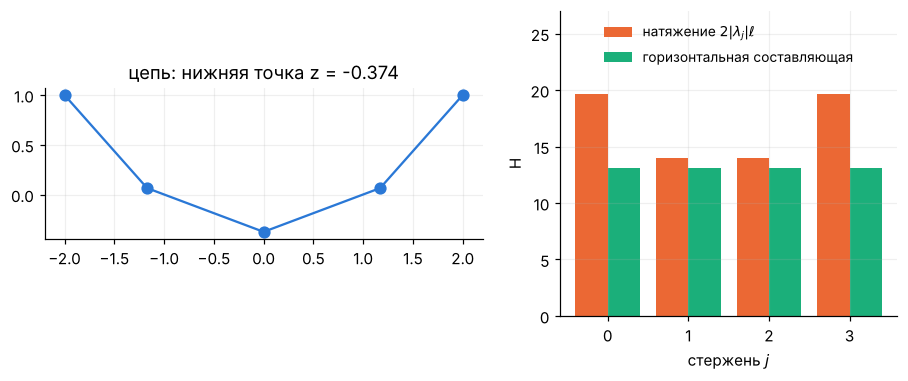

In [10]:
Fh, Fv = chk["Fh"], chk["Fv"]                                          # горизонтальная и вертикальная составляющие силы стержня j
print(f"горизонтальные 2 lambda_j dy_j: {Fh.round(3)} Н")
print(f"вертикальные   2 lambda_j dz_j: {Fv.round(3)} Н")
print(f"вертикальные на опорах: {abs(Fv[0]):.2f} + {abs(Fv[-1]):.2f} = {abs(Fv[0]) + abs(Fv[-1]):.2f} Н, вес цепи {ch['w'] * ch['N']:.2f} Н")
y, z = chain_xy(ch, v)                                                 # координаты с опорами
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw=dict(width_ratios=[1.3, 1]))
axes[0].plot(y, z, "o-", color=BLUE, ms=7); axes[0].set_aspect("equal"); axes[0].set_title(f"цепь: нижняя точка z = {z.min():.3f}")
j = np.arange(4)                                                       # номера стержней
axes[1].bar(j - 0.2, chk["F"], 0.4, color=ORANGE, label="натяжение $2|\\lambda_j|\\ell$")
axes[1].bar(j + 0.2, np.abs(Fh), 0.4, color=AQUA, label="горизонтальная составляющая")
axes[1].set_xticks(j); axes[1].set_xlabel("стержень $j$"); axes[1].set_ylabel("Н"); axes[1].set_ylim(0, 27)
axes[1].legend(fontsize=9, loc="upper center")
plt.show()

**Что видим.** Горизонтальная составляющая одна и та же во всех стержнях — это первое уравнение баланса из §5.1. Вертикальные: $14.72$, $4.91$, $-4.91$, $-14.72$. Соседние отличаются на вес груза $9.81$ — это второе уравнение. На опорах — по $14.72$ Н, вместе $29.43$ Н, ровно вес цепи.

## 6. Что это даёт численно

**Главная мысль.** Солвер решает ту же систему $\nabla_xL=0$, $g=0$. Его лог — две невязки этой системы.

**Где множители.** У солверов функция Лагранжа $f+\lambda^\top g$, поэтому знак множителей противоположный нашему:

| Солвер | Где множители | Наш $\lambda$ |
|---|---|---|
| IPOPT через CasADi | `sol["lam_g"]` | $-$`lam_g` |
| SciPy, `method="trust-constr"` | `res.v` | $-$`v` |

**Как проверить ответ.** Подставьте $x^\ast$ и $\lambda^\ast$ в систему §2.3 и посчитайте обе невязки.

**Что в логе IPOPT.** Две колонки лога — невязки двух половин системы:

- `inf_pr` — нарушение ограничений $\lVert g(x_k)\rVert_\infty$;
- `inf_du` — невязка стационарности $\lVert\nabla_xL(x_k,\lambda_k)\rVert_\infty$.

Солвер останавливается, когда обе меньше допуска `tol`.

<img src="img/09_ipopt_residuals.png" width="750" alt="невязки IPOPT на цепи на стержнях по пяти итерациям в логарифмической шкале: обе падают всё быстрее, inf_pr на последних итерациях 2.5e−4, 1.5e−7, 3e−13; пунктир — tol = 1e−8">

*Цепь на стержнях, 5 итераций. В конце число верных знаков примерно удваивается за итерацию: $2.5\cdot10^{-4}\to1.5\cdot10^{-7}\to3\cdot10^{-13}$.*

Так сходится метод Ньютона: IPOPT делает его шаги для этой системы. В лекции 9 мы напишем такой метод сами.

## 7. Итоги лекции

1. В минимуме на поверхности $g(x)=0$ у $\nabla f$ нет касательной части: $\nabla f=J^\top\lambda$ (§2).
2. Функция Лагранжа $L=f-\lambda^\top g$ даёт систему $\nabla_xL=0$, $g=0$: $n+m$ уравнений на $x$ и $\lambda$ (§2.3).
3. Условие касания верно при LICQ. Без LICQ формула $Jp=0$ может дать направления, которых нет (плоскость касается сферы), и в минимуме условие не выполняется (§3).
4. Минимум от максимума отличает редуцированный гессиан $Z^\top\nabla^2_{xx}L\,Z$. Кривизна ограничений входит в него через $-\lambda\nabla^2g$ (§4).
5. Множитель — сила ограничения и его цена: $df^\ast/db=\lambda^\ast$ (§5).

**Ответы на задачи введения.**

- **Задача 1.** Редуцированный гессиан равен $+2.236$ в ближней точке и $-2.236$ в дальней: это минимум и максимум.
- **Задача 2.** Четыре множителя — натяжения стержней: 19.7 Н у опор и 14.0 Н в середине. Горизонтальная составляющая — 13.1 Н во всех стержнях. Оба собственных числа редуцированного гессиана положительны, значит, это минимум.

## 8. Что дальше

**Лекция 9** — алгоритмы для равенств. Метод Ньютона для системы $\nabla_xL=0$, $g=0$ (Ньютон–Лагранж), обобщённый Гаусс–Ньютон и цепь на стержнях своим методом против IPOPT. **Лекция 10** — неравенства: условия ККТ и двойственность.

ДЗ 5 (Ньютон–Лагранж и обобщённый Гаусс–Ньютон) выдаётся после лекции 9.

**Литература к лекции.**
- Diehl, *Lecture Notes on Numerical Optimization*, часть III, глава *Equality Constrained Optimization*: касательное пространство, LICQ, условия первого и второго порядка.
- Nocedal & Wright, гл. 12: §12.1 — примеры, §12.2 — касательный конус и LICQ, §12.3 — теорема первого порядка, §12.5 — условия второго порядка.
- Boyd & Vandenberghe, §10.1 — задачи с равенствами и система ККТ; §5.6 — множители как чувствительность.

## 9. Упражнения

Разбор с проверкой кодом — [`exercises08.ipynb`](exercises08.ipynb), краткие ответы — [`exercises08.md`](exercises08.md). На семинаре — 8.0 и 8.3, остальные — домашние.

**8.0. Разминка — счёт руками.** *Суть: система $\nabla_xL=0$, $g=0$ на задачах с известным ответом.*

- (а) Ближайшая к $x_0$ точка плоскости $q^\top x=d$. Выпишите $L$ и решите систему. Сравните ответ с проекцией из лекции 2.
- (б) $\min\ x_1+x_2$ при $x_1^2+x_2^2=1$. Найдите оба решения системы и их $\lambda$. Какое из них минимум?
- (в) Ящик наибольшего объёма при площади поверхности $6$ (Л3, упражнение 13.10). Найдите $\lambda$ в решении $x=y=z=1$ и объясните его знак.

**8.1. Две точки на окружности** (с кодом). *Суть: редуцированный гессиан различает минимум и максимум.*

- (а) Решите систему из §2.1 функцией `fsolve` из двух стартов. Получите обе точки и оба $\lambda$.
- (б) Для каждой точки постройте $Z$ (`null_space`) и редуцированный гессиан. Повторите для $a=(0.3,\ 0.1)$. Что изменилось?

**8.2. Плоскость касается сферы** (с кодом). *Суть: у касания множители уходят в бесконечность, а солвер теряет точность.*

- (а) Решите задачу §3.1 при $c<1$ руками: найдите $x^\ast$ и покажите, что $\lambda_1=1-\sqrt5/\sqrt{1-c^2}$. Сравните с IPOPT при $c=0.9,\ 0.99,\ 0.999$.
- (б) Окружности радиуса 1 с центрами $(\pm1,\ 0)$ касаются в нуле. Найдите $\min x_2$ на их пересечении. Выполнено ли LICQ? Что вернёт IPOPT?

**8.3. Кривизна ограничения.** *Суть: решает $\nabla^2_{xx}L$ вдоль $T$, а не $\nabla^2f$.*

- (а) $f=x_2$ на параболе $x_2=cx_1^2$. При каких $c$ ноль — минимум, максимум, ни то ни другое?
- (б) $f=x_1^2-x_2^2$ на прямой $x_2=0$. Покажите, что ноль — строгий минимум, хотя $\nabla^2f$ индефинитен (собственные числа разных знаков).

**8.4. Цепь на стержнях: силы и цена длины** (с кодом). *Суть: условие первого порядка — баланс сил, а множитель — производная оптимума.*

- (а) Решите задачу 2 из введения в CasADi. Проверьте: горизонтальная составляющая $2\lambda_j\Delta y_j$ одинакова во всех стержнях, а вертикальные составляющие на опорах дают вес цепи.
- (б) Удлините стержни на $1\,\%$ и на $5\,\%$. Сравните изменение $f^\ast$ с предсказанием $\sum_j\lambda_j\,\Delta(\ell^2)$. Почему при $5\,\%$ расхождение больше?

**8.5. Цена доходности** (с кодом). *Суть: $df^\ast/d\rho=\lambda_\rho$.*

Решите систему для портфеля из §5.2 при $\rho$ от $6$ до $14\,\%$. Почему она линейная? Сравните численную производную $f^\ast(\rho)$ с $\lambda_\rho$. При какой $\rho$ доля первого актива становится отрицательной?

**8.6. Для желающих: доказательства.** *Суть: теорема о неявной функции превращает задачу с равенствами в задачу без них.*

Докажите теоремы §3.2 и §4.2 полностью. Докажите формулу цены из §5.2 и найдите условие, при котором $x^\ast(b)$ и $\lambda^\ast(b)$ дифференцируемы.

## Вопросы для самопроверки

1. Почему в минимуме у $\nabla f$ нет касательной части?
2. Сколько уравнений и неизвестных в системе первого порядка при $n$ переменных и $m$ ограничениях?
3. Что такое LICQ? Приведите пример минимума, в котором условие касания не выполняется.
4. Почему второй порядок проверяют по $\nabla^2_{xx}L$, а не по $\nabla^2f$?
5. Что такое редуцированный гессиан и какого он размера?
6. Почему натяжение стержня равно $2\lvert\lambda_j\rvert\ell$?
7. Что показывают колонки `inf_pr` и `inf_du` в логе IPOPT?
8. Ограничение $x_1+x_2=1$ записано дважды. Найдёт ли солвер минимум? Что будет с множителями?